<a href="https://colab.research.google.com/github/rahulsapkota01/Rahul_INFO4670_Fall2026/blob/main/Logistic_Regression_Car_Assignment_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 11: Assignment 4 - Logistic Regression Assignment (Age & Salary → Purchased)
**Coures:** INFO 4670 Fengjiao Tu  
**Goal:** Train and evaluate a Logistic Regression model to predict whether a customer purchases a car using `Age` and `Salary`.

---

## I. Assignment Objective
By completing this assignment, you will:
- Understand the concept and intuition of logistic regression.
- Load and preprocess data using `pandas`.
- Train and evaluate a logistic regression model with `scikit-learn`.
- Visualize classification results.
- Analyze model performance and reflect on possible improvements.


## II. Dataset Description
Expected CSV file name: **`car_purchase_data.csv`**

| Column | Description | Example |
|--------|-------------|---------|
| `Age` | Age of the customer | 35 |
| `Salary` | Annual or monthly income | 60000 |
| `Purchased` | Whether the customer purchased a car (1 = Yes, 0 = No) | 1 |


---
# Grading Rubric (Total = 100 points)

| Section | Description | Points | Details |
|--------|-------------|--------|---------|
| **Objective Understanding** | Explain purpose and logic of logistic regression | 10 | Goal & rationale (5); why LR for this task (5) |
| **Data Preparation** | Data loading, splitting, scaling | 20 | Import & preview (5); X/y split (5); train/test (5); scaling (5) |
| ** Model Training & Evaluation** | Fit, predict, metrics, visualization | 40 | Trained correctly (10); metrics shown (10); **accuracy ≥ 87.5% (10)**; visualization (10) |
| ** Analysis & Reflection** | Interpretation and critical thinking | 30 | Probability→class explanation (10); result discussion (10); improvements (10) |


**Accuracy Requirement:**
- Full credit (10 pts) if **accuracy ≥ 87.5%**
- Partial (7–9 pts) if **80% ≤ accuracy < 87.5%**
- Minimal (≤5 pts) if **accuracy < 80%**
- 0 pts if the model fails to run


## III. Steps to Complete
Follow the cells below in order. According to the hands-on task, please complete the code.

### Step 1: Import libraries and load data

In [8]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

df = pd.read_csv("car_purchase_data.csv")
print(df.head())
print(df.info())


    User ID  Gender  Age  Salary  Purchased
0  15624510    Male   19   19000          0
1  15810944    Male   35   20000          0
2  15668575  Female   26   43000          0
3  15603246  Female   27   57000          0
4  15804002    Male   19   76000          0
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 5 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   User ID    400 non-null    int64 
 1   Gender     400 non-null    object
 2   Age        400 non-null    int64 
 3   Salary     400 non-null    int64 
 4   Purchased  400 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 15.8+ KB
None


### Step 2: Split features and target

In [9]:

X = df[['Age', 'Salary']]
y = df['Purchased']

print("Features:")
print(X.head())
print("Target:")
print(y.head())


Features:
   Age  Salary
0   19   19000
1   35   20000
2   26   43000
3   27   57000
4   19   76000
Target:
0    0
1    0
2    0
3    0
4    0
Name: Purchased, dtype: int64


### Step 3: Train/Test Split

In [10]:

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=10, stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)


Training data: (320, 2)
Testing data: (80, 2)


### Step 4: Feature Scaling

In [11]:

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(X_train_scaled[:5])



[[-1.33732861 -1.27939578]
 [-1.53372382 -0.20827373]
 [-1.82831663 -1.45791612]
 [ 2.09958751  2.17199748]
 [-0.64994539  0.56531441]]


### Step 5: Train Logistic Regression Model

In [12]:

model = LogisticRegression(random_state=10)
model.fit(X_train_scaled, y_train)

print("Model trained successfully!")


Model trained successfully!


### Step 6: Predict and Evaluate

In [13]:

y_pred = model.predict(X_test_scaled)

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)
print("Accuracy Percentage:", round(accuracy * 100, 2), "%")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))


Accuracy: 0.9
Accuracy Percentage: 90.0 %

Confusion Matrix:
[[49  2]
 [ 6 23]]

Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.96      0.92        51
           1       0.92      0.79      0.85        29

    accuracy                           0.90        80
   macro avg       0.91      0.88      0.89        80
weighted avg       0.90      0.90      0.90        80



### Step 7: Visualization of Decision Regions

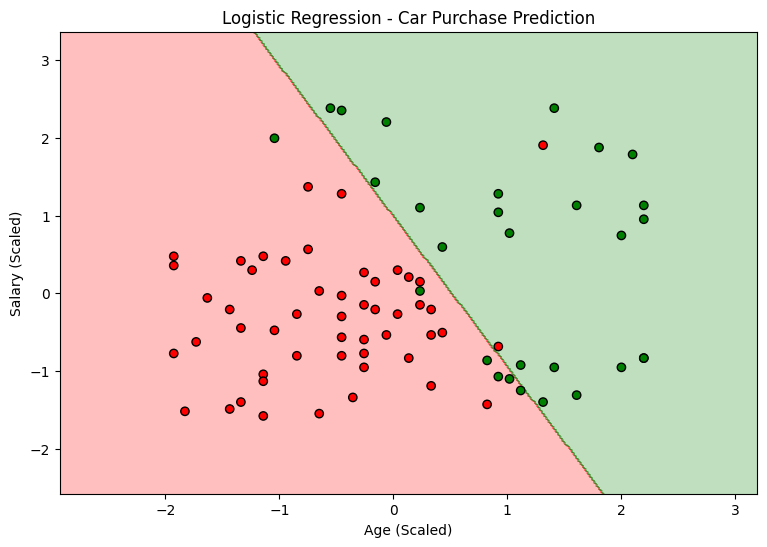

In [14]:

from matplotlib.colors import ListedColormap

X_set = X_test_scaled
y_set = y_test.to_numpy()

x1, x2 = np.meshgrid(
    np.arange(X_set[:, 0].min() - 1, X_set[:, 0].max() + 1, 0.02),
    np.arange(X_set[:, 1].min() - 1, X_set[:, 1].max() + 1, 0.02)
)

grid = np.c_[x1.ravel(), x2.ravel()]
predictions = model.predict(grid).reshape(x1.shape)

plt.figure(figsize=(9, 6))

plt.contourf(
    x1, x2, predictions,
    alpha=0.25,
    cmap=ListedColormap(['red', 'green'])
)

plt.scatter(
    X_set[:, 0], X_set[:, 1],
    c=y_set,
    cmap=ListedColormap(['red', 'green']),
    edgecolors='black'
)

plt.title("Logistic Regression - Car Purchase Prediction")
plt.xlabel("Age (Scaled)")
plt.ylabel("Salary (Scaled)")
plt.show()


## IV. Reflection Questions
1. Logistic regression outputs probabilities — why can it still be used for classification?
2. Based on your model, which customers are more likely to purchase a car?
3. What factors might cause low accuracy in this task?
4. Propose additional features or preprocessing steps that could improve accuracy.


1. Logistic regression gives a probability between 0 and 1. If the probability is 0.5 or higher, it predicts Yes (1). If it is below 0.5, it predicts No (0).

2. Older customers with higher salaries are generally more likely to purchase a car.

3. Low accuracy can happen because of missing information, incorrect data, or a small dataset. Age and salary alone may not be enough to predict car purchases.

4. We could add more information, such as credit score, savings, job status, and family size. We could also clean the data, remove duplicates, and test different model settings to improve accuracy.
